--- Starting Training ---
Target to match -> Mean: [-4.0, 1.0], Scale: [2.0, 1.5]

Step   0 | Loss: 2.2750
Step 100 | Loss: -0.1640
Step 200 | Loss: -0.0852
Step 300 | Loss: -0.0855
Step 400 | Loss: -0.0789
Step 500 | Loss: -0.0935
Step 600 | Loss: -0.0574
Step 700 | Loss: -0.1599
Step 800 | Loss: 0.0355
Step 900 | Loss: -0.0470
Step 1000 | Loss: -0.1497


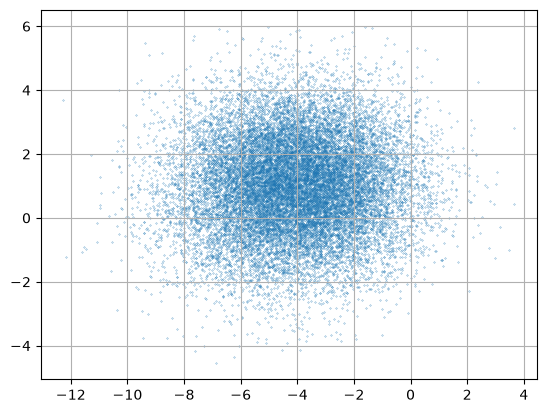

Target Mean:  tensor([-4.,  1.])
Learned Mean: tensor([-4.1104,  0.9927])
Target Scale: tensor([2.0000, 1.5000])
Learned Scale:tensor([2.0627, 1.4701])
done


In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt

class RealNVP(nn.Module):
  def __init__(self):
    super().__init__()
    self.T1 = nn.Sequential(
        nn.Linear(1, 64),
        nn.ReLU(),
        nn.Linear(64, 64),
        nn.ReLU(),
        nn.Linear(64, 1)
    )
    self.S1 = nn.Sequential(
        nn.Linear(1, 64),
        nn.ReLU(),
        nn.Linear(64, 64),
        nn.ReLU(),
        nn.Linear(64, 1)
    )
    self.T2 = nn.Sequential(
        nn.Linear(1, 64),
        nn.ReLU(),
        nn.Linear(64, 64),
        nn.ReLU(),
        nn.Linear(64, 1)
    )
    self.S2 = nn.Sequential(
        nn.Linear(1, 64),
        nn.ReLU(),
        nn.Linear(64, 64),
        nn.ReLU(),
        nn.Linear(64, 1)
    )

  def forward(self, z):
    z1, z2 = torch.chunk(z, 2, dim=1)

    # print("z=",z)
    # print("z1=",z1)
    # print("z2=",z2)

    # print("z=",z)
    # print("z1=",z1)
    # print("z2=",z2)
    #print(self.S(z1).shape)

    # might want multiple blocks (for loop??)
    y1 = z1
    y2 = (z2-self.T1(z1)) * torch.exp(-self.S1(z1))

    x1 = y2
    x2 = (y1-self.T2(y2)) * torch.exp(-self.S2(y2))

    x1, x2 = x2, x1

    #print(x1)
    #print(x2)

    x = torch.cat((x1, x2), dim=1)

    #print("x=",x)

    log_det_Jzy = -torch.sum(self.S1(z1), dim=1)
    log_det_Jyx = -torch.sum(self.S2(y2), dim=1)
    total_log_det = log_det_Jzy + log_det_Jyx

    return x, total_log_det

num_samples = 512

target_mean = torch.tensor([-4.0, 1.0])
target_scale = torch.tensor([2.0, 1.5])

def compute_boltzmann_energy(x):
    normalized = (x - target_mean) / target_scale
    energy = 0.5 * torch.sum(normalized ** 2, dim=1)
    return energy

model = RealNVP()
optimizer = optim.Adam(model.parameters(), lr=0.001)

print("--- Starting Training ---")
print(f"Target to match -> Mean: {target_mean.tolist()}, Scale: {target_scale.tolist()}\n")

# 4. The Training Loop
for step in range(1001):
    optimizer.zero_grad()

    # A. Generate base samples (noise from standard normal distribution)
    base_samples = torch.randn(num_samples, 2)
    #print(base_samples)

    # B. Pass samples through the flow network
    x, log_det = model(base_samples)

    # print("x size=", x.size())
    # print(log_det)

    # C. Compute Loss (Variational Free Energy)
    potential_energy = compute_boltzmann_energy(x)
    loss = torch.mean(potential_energy - log_det)

    # D. Backpropagation & Optimization
    loss.backward()       # PyTorch calculates gradients automatically
    optimizer.step()      # Optimizer updates weights (scale and shift parameters)

    # Print progress every 100 steps
    if step % 100 == 0:
        # current_scales = torch.exp(model.scale_param).detach().numpy()
        # current_shifts = model.shift_param.detach().numpy()
        #print("log_det = ", log_det)
        #print("potential energy = ", torch.mean(potential_energy).item())
        print(f"Step {step:3d} | Loss: {loss.item():.4f}")
        #print("")

# After training is finished:
model.eval()  # Set model to evaluation mode
with torch.no_grad():
    # Generate 10,000 fresh test samples
    test_noise = torch.randn(20000, 2)
    generated_samples, _ = model(test_noise)

    x = generated_samples[:,0]
    y = generated_samples[:,1]

    plt.scatter(x,y, s=0.05)
    plt.grid()
    plt.show()

    #transformed_samples = 
    
    # Calculate empirical mean and scale (standard deviation) of generated points
    emp_mean = generated_samples.mean(dim=0)
    emp_scale = generated_samples.std(dim=0)
    
    print(f"Target Mean:  {target_mean}")
    print(f"Learned Mean: {emp_mean}")
    print(f"Target Scale: {target_scale}")
    print(f"Learned Scale:{emp_scale}")

print("done")